# Lab 6, Task 1A: MIMO Channel Estimation and Capacity

Estimate a 2 by 2 channel and compare equal-total-power MIMO and SISO capacity.

In [6]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Image

def find_lab_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "support" / "lab6_dsp.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the Lab 6 folder tree")

LAB_ROOT = find_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
import lab6_dsp as lab
import lab6_tools as tools
print("Lab folder:", LAB_ROOT.name)

Lab folder: Lab6


## Simulation settings

Use the SNR values and number of channel realizations specified in the manual.

In [2]:
snr_db = np.arange(0, 26, 5)
realizations = 5000
results = lab.simulate_mimo_capacity(snr_db, realizations=realizations, seed=7601)
print('SNR (dB):', results['snr_db'])
print('Mean 2x2 capacity:', np.round(results['mimo_capacity_bps_hz'], 3))

SNR (dB): [ 0.  5. 10. 15. 20. 25.]
Mean 2x2 capacity: [ 2.578  3.792  5.775  8.376 11.367 14.531]


## One least-squares calculation

For $Y=HX+N$, use $\hat H=YX^H(XX^H)^{-1}$. The array dimensions are receive branches by samples for `y`, and transmit branches by samples for `x`.

In [3]:
rng = np.random.default_rng(6)
h_true = np.array([[0.8+0.2j, -0.3+0.5j], [0.4-0.1j, 0.7+0.3j]])
x = (rng.standard_normal((2, 2000)) + 1j*rng.standard_normal((2, 2000))) / np.sqrt(2)
y = h_true @ x

h_hat = (y @ x.conj().T) @ np.linalg.inv(x @ x.conj().T)
print('Estimated H:\n', np.round(h_hat, 4))
print('Maximum coefficient error:', np.max(np.abs(h_hat-h_true)))

Estimated H:
 [[ 0.8+0.2j -0.3+0.5j]
 [ 0.4-0.1j  0.7+0.3j]]
Maximum coefficient error: 2.2887833992611187e-16


## Capacity calculation

Use $C=\log_2\det(I_{N_r}+(\rho/N_t)HH^H)$. `rho` is linear total receive SNR.

In [18]:
rho_db = 15.0

rho = 10**(rho_db / 10)
capacity = np.log2(np.linalg.det(np.eye(h_hat.shape[0]) + (rho / h_hat.shape[1]) * (h_hat @ h_hat.conj().T))).real
print(f'Capacity at {rho_db:.1f} dB: {capacity:.3f} bit/s/Hz')

Capacity at 15.0 dB: 6.856 bit/s/Hz


## Expected plot

The plotting code is supplied.

<span style='color:#1464b4'><b>Report:</b> Explain why MIMO capacity depends on both SNR and channel rank. </span>

MIMO capacity increases with SNR because stronger signal levels improve data transmission reliability. Capacity also depends on channel rank, since higher-rank channels support more independent spatial streams. This is reflected in Figure 1, where the 2×2 MIMO capacity increases with SNR and remains higher than the individual SISO capacities.

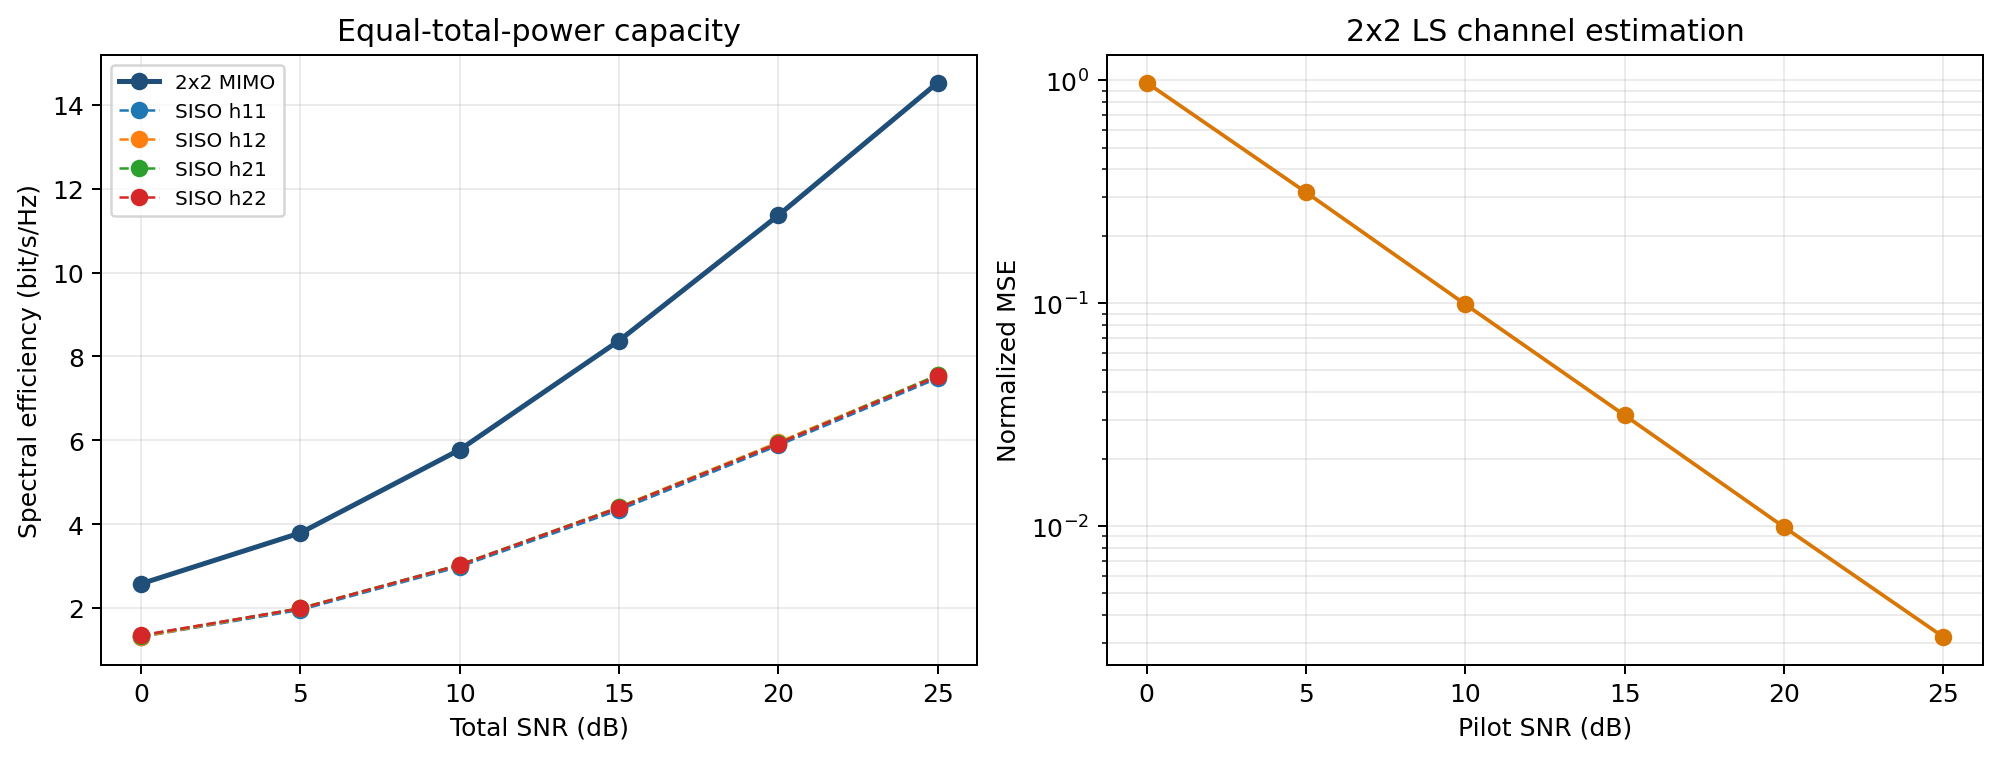

In [19]:
display(Image(filename=str(LAB_ROOT/'expected_figures/task1_mimo_capacity_and_estimation.png'), width=900))

<span style='color:#1464b4'><b>Report:</b> Include a short interpretation of channel rank and estimation error.</span>

Channel rank determines how many independent spatial streams the MIMO channel can support. Higher-rank channels provide more spatial diversity and higher capacity, which is reflected in Figure 1 by the consistently higher 2×2 MIMO capacity compared to the individual SISO links. Channel estimation error measures how closely the estimated channel matches the true channel. As SNR increases like in Figure 2, the normalized MSE decreases, resulting in more accurate channel estimates and more reliable capacity calculations.